# Variables condicionantes

## Objetivos de aprendizaje

Al finalizar este capítulo, el estudiante será capaz de:

- Identificar y justificar las variables condicionantes relevantes para la ocurrencia de movimientos en masa en zonas montañosas.
- Cargar y procesar mapas raster de variables topográficas, geológicas e hidrológicas con `rasterio` y `numpy`.
- Construir un `DataFrame` de `pandas` que integre múltiples capas raster como columnas.
- Realizar análisis univariado y bivariado de las variables condicionantes usando histogramas, boxplots, KDE y PCA.
- Interpretar la capacidad discriminante de cada variable respecto al inventario.

**Duración estimada:** 3–4 horas

## Requisitos previos

- **Python:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn` (PCA).
- **SIG:** datos raster, pendiente, aspecto, acumulación de flujo, geología superficial.
- **Estadística:** estadística descriptiva (media, mediana, cuartiles), correlación, análisis de componentes principales (PCA).
- **Capítulo anterior:** `05_inventario` — el inventario de movimientos en masa se usa como variable respuesta.

Como se mencionó anteriormente la elaboración de un mapa de susceptibilidad y/o amenaza por movimientos en masa se refiere a la construcción de un modelo predictivo de la siguiente forma:

$y = f(X)$

Donde $y$ es la variable dependiente, es decir la ocurrencia o no de movimientos en masa; y $X$ corresponde a las variables independientes, o también llamadas condicionantes, preparatorias, explicativas, cuasi-estáticas, predictoras, entre otros nombres asignados. y $f$ representa la relación, función o el mecanismo que explica la ocurrencia de movimientos en masa. 

$MenM[0,1] = f(pendiente, geologia, coberturas, etc, etc,)$

:::{figure-md} variables-tabla
<img src="https://www.cdema.org/virtuallibrary/images/description/23%20table%201.jpg" alt="variables" width="800px">

Variables para la evaluación de la susceptibilidad por movimientos en masa. Tomado de CDEMA & CRIS.
:::

Las propiedades del suelo y la intensidad de la lluvia (I) son un factor primario que controla la inestabilidad de los taludes; la magnitud y tasa de reducción en el factor de seguridad (FS) es directamente proporcional a la magnitud de la intensidad de lluvia, a mayor intensidad más rápidamente decrece el factor de seguridad ({cite:t}`rahardjo2007`). Adicionalmente pequeñas variaciones en la conductividad hidráulica (k) controlan la localización de la ocurrencia de movimientos en masa, lo que explica de cierta forma el carácter aleatorio en la distribución de los movimientos sobre una misma ladera aparentemente homogénea ({cite:t}`reid1997`). {cite:t}`cho2001` y {cite:t}`cho2002` estudian los mecanismos de falla en taludes conformados por suelos residuales no saturados donde encuentran que el campo de los esfuerzos es modificado por la distribución de la presión de poros (Ψ), la cual es controlada por las variaciones espaciales de la conductividad hidráulica durante la infiltración de la lluvia. Y aunque el talud es homogéneo texturalmente, la conductividad hidráulica tiene una distribución no homogénea ya que es una función del contenido de agua o de la succión.

:::{figure-md} variables-esquema
<img src="https://i.pinimg.com/564x/96/21/fe/9621fe215adc31032b8e493a3382da1d.jpg" alt="variables" width="600px">

Representación esquemática tridimensional del perfil de meteorización sobre una ladera de morfología (ML) convergente bajo lluvia (P) y las variables hidrológicas - geotécnicas que influyen en la  ocurrencia de movimientos en masa: intensidad de la precipitación (I), contenido de agua volumétrico (ө), presión de poros positiva (Ψ+) y negativa o succión (Ψ-), permeabilidad (k), peso del suelo (W), vegetación (V), infiltración, pendiente de la ladera (β), resistencia al cortante (ז), profundidad (Z), espesor suelo saturado (h).
:::

De acuerdo con la mecánica descrita anteriormente la complejidad en encontrar las probabilidades de alcanzar el aumento de presión de poros crítica y por lo tanto pronosticar la ocurrencia de movimientos en masa detonados por lluvias es función de una gran cantidad de variables involucradas e íntimamente relacionadas. El aumento de la presión de poros en el suelo es función de la porosidad, la permeabilidad, la conductividad hidráulica, y el contenido de agua en el suelo. Por otra parte la pendiente y morfología del terreno juegan un papel fundamental que controlan no solo la resistencia del suelo, sino además el flujo del agua en el suelo. 

La **permeabilidad** controla el balance que debe existir entre la generación de la presión de poros y su disipación, lo cual es fundamental para la inicialización del movimiento ({cite:t}`wang2007`). El efecto de la lluvia antecedente es más crítico para suelos con bajos valores de permeabilidades, debido a que el tiempo requerido para que la lluvia infiltre es muy largo y la recuperación del factor de seguridad después de una lluvia es muy lento ({cite:t}`hengxing2003`,{cite:t}`setyo2008`, {cite:t}`rahardjo2007`). Esta situación también explica que los mecanismos de falla para laderas con diferentes permeabilidades no son similares. Bajo lluvias intensas, suelos de alta permeabilidad usualmente fallan por aumento de presiones de poro positiva como movimiento tipo flujos, mientras suelos de baja permeabilidad fallan por reducción de la succión como movimientos tipo deslizamientos. 

Adicionalmente pequeñas variaciones en la **conductividad hidráulica** controlan la localización de la ocurrencia de movimientos en masa ya que es una función del contenido de agua o de la succión, lo que explica de cierta forma el carácter aleatorio en la distribución de los movimientos ({cite:t}`reid1997`, {cite:t}`cho2001`, {cite:t}`cho2002`). La capilaridad proporciona una presión de confinamiento isotrópico que disminuye la conductividad hidráulica cuando el suelo no está saturado, pero durante una tormenta, el suelo se acerca a condiciones de saturación, por lo que la conductividad es más alta ({cite:t}`anderson1995`). Los suelos residuales son susceptibles a la formación de conductos debido a las articulaciones relictas y efectos biológicos; y desarrollan un sistema de porosidad secundaria, el cual aumenta sustancialmente la permeabilidad y conductividad hidráulica de los suelos y actúan como trayectorias de flujo preferenciales para los flujos del subsuelo ({cite:t}`fernandes2004`).
 La dinámica del frente de humedecimiento durante una tormenta puede distinguirse en tres estados de flujo lateral: durante el humedecimiento, el agua que se infiltra genera un fuerte gradiente de succión normal e interno a la superficie de la ladera, induciendo un vector de flujo lateral hacia arriba (upslope) en las cercanías del frente húmedo; durante el secado, al disminuir la intensidad de la lluvia o cesar la tormenta, la redistribución y el drenaje del agua generan un estado donde dominan las fuerzas de gravedad y se produce un fuerte flujo lateral cuesta abajo (downslope); y en la zona cuasi-estacionaria, detrás del frente de humedecimiento se establece un régimen de flujo neutro y constante, con una trayectoria de flujo vertical descendente gobernado puramente por la gravedad. Adicionalmente, en laderas heterogéneas y estratificadas, las diferencias texturales y de conductividad hidráulica imponen barreras capilares que alteran críticamente la estabilidad local del flujo subsuperficial.
:::{figure-md} permeabilidad
<img src="https://ars.els-cdn.com/content/image/1-s2.0-S0038071721002728-gr1.jpg" alt="permeabilidad" width="600px">

Contenido de agua en el suelo por diferentes tipos de flujos preferenciales. Tomado de {cite:t}`franklin2021`.
:::

Otro elemento importante es la **porosidad efectiva**. La capacidad de almacenamiento del agua en el suelo depende de los espacios abiertos o poros que se encuentran en el suelo y está determinada principalmente por la textura del suelo. Suelos con alta porosidad efectiva presentan una mayor capacidad para mantener y almacenar agua, y por lo tanto retrasan la infiltración en el sub suelo. Para tormentas no muy intensas, no se presentan movimientos superficiales cuando existen altos valores de porosidad efectiva. Sin embargo estos altos valores tienden a aumentar el contenido de agua de la masa desplazada, lo que genera finalmente movimientos más rápidos y que recorren mayores distancias, además de depositarse sobre áreas más extensas ({cite:t}`mukhlisin2006`). 

Aunque es conocida la **lluvia antecedente** como un factor importante que predispone las condiciones de inestabilidad de una ladera, su influencia es difícil de cuantificar, ya que depende de diferentes factores entre ellos la heterogeneidad de los suelos ({cite:t}`guzzetti2005`, {cite:t}`rahardjo2007`). Los movimientos superficiales son usualmente detonados por lluvias cortas e intensas, en tanto que los movimientos profundos están más relacionados con la distribución y variación de la lluvia en periodos antecedentes largos ({cite:t}`aleotti2004`). Diferentes investigadores coinciden en que la importancia de la lluvia antecedente es igual a la intensidad de la lluvia y depende de la permeabilidad del suelo ({cite:t}`guzzetti2005`, {cite:t}`rahardjo2007`). En general existe consenso en que para suelos de baja permeabilidad y conductividad hidráulica la lluvia antecedente juega un rol muy importante, ya que luego de la ocurrencia de lluvias conserva las presiones de poros positivas por tiempos mayores ({cite:t}`hengxing2003`, {cite:t}`rahardjo2008`). 

:::{figure-md} lluvia-antecedente
<img src="https://media.springernature.com/lw685/springer-static/image/art%3A10.1007%2Fs10346-020-01505-4/MediaObjects/10346_2020_1505_Fig4_HTML.png" alt="lluvia antecedente" width="600px">

Lluvia antecedente. Tomado de {cite:t}`kim2021`.
:::

La **succión** es uno de las variables más importantes de esfuerzos en la teoría de suelos no saturados ({cite:t}`fredlund1977`, {cite:t}`fredlund1993`, {cite:t}`fredlund1993`). Para suelos no saturados la permeabilidad es función de la succión debido a la distribución heterogénea de los poros y el agua dentro de la masa de suelo. La cantidad de agua almacenada depende también de la succión de la matriz y la retención de humedad característica de la estructura del suelo ({cite:t}`ng1998`). Con la reducción del contenido volumétrico de agua, la succión y consecuentemente la conductividad hidráulica decrecen, debido al número menor de poros conectados dentro de la estructura del suelo que decrece el número de canales disponibles para el flujo de agua ({cite:t}`collins2004`). Suelos de grano fino no tienden a desarrollar presiones de poros positivas y la falla ocurre generalmente por pérdida de succión.
 Formalmente, la succión se incorpora a la mecánica de suelos no saturados a través del principio de esfuerzos efectivos de Bishop, expresado como sigma' = sigma - u_a - sigma^s, donde sigma es el esfuerzo total, u_a es la presión del aire en los poros y sigma^s es la tensión de succión, la cual integra cinemáticamente fuerzas capilares (meniscos de agua y tensión superficial) y fuerzas físico-químicas de atracción y repulsión (fuerzas de van der Waals y de la doble capa eléctrica) a escala microscópica. La relación entre la tensión de succión y la saturación --definida mediante la curva característica de la tensión de succión (SSCC), intrínsecamente ligada a la curva de retención de agua (SWRC)-- difiere sustancialmente según el tipo de suelo: los suelos arenosos (granulares) presentan un comportamiento no monótono, con tensión de succión igual a cero tanto en estado completamente seco (sin agua para formar meniscos) como en estado completamente saturado (desaparición de la tensión superficial), y con una magnitud máxima muy pequeña, de apenas unos pocos kPa; mientras que los suelos arcillosos (finos) exhiben un comportamiento monótono.
:::{figure-md} succion
<img src="https://www.researchgate.net/profile/Rukshan-Azoor/publication/334659960/figure/fig5/AS:793496080379906@1566195616832/Schematic-of-the-soil-water-retention-curve-SWRC-illustrating-the_W640.jpg" alt="succion" width="600px">

Curva característica esquemática de retención de agua en el suelo. Tomado de [Azoor et al., 2019](https://www.researchgate.net/publication/334659960_On_the_optimum_soil_moisture_for_underground_corrosion_in_different_soil_types).
:::

Pocos estudios se han realizado sobre el efecto de la **vegetación** y el desarrollo de sus raíces sobre la ocurrencia de los movimientos en masa. Entre los estudios más reportados se encuentran {cite:t}`o1986`, {cite:t}`gray1995`, {cite:t}`wu1995`, {cite:t}`ziemer1981`, {cite:t}`normaniza2006`, {cite:t}`tosi2007`, y {cite:t}`normaniza2008`. En general la mayoría de autores han evaluado el efecto mecánico que generan las raíces de las plantas en la estabilidad de las laderas, atribuido principalmente al incremento en la resistencia al cortante de los suelos. Este incremento se le atribuye al anclaje de las raíces formando una red dentro de los horizontes de suelos más superficiales. Sin embargo es conocido que la vegetación influencia la estabilidad de las laderas en dos formas esencialmente: (i) removiendo la humedad del suelo por evapotranspiración; y (ii) generando cohesión por las raíces en el manto del suelo ({cite:t}`sidle2006`). El primero de ellos no se considera particularmente importante en regiones para movimientos en masa superficiales que se generan en periodos lluviosos, excepto posiblemente en los trópicos y subtrópicos donde la evapotranspiración es alta durante todo el año. Las raíces, por su parte, son reconocidas como un factor más importante en la estabilidad de las vertientes, las cuales pueden responder a la fuerza de corte en tres diferentes formas: estirándose, deslizándose o rompiéndose ({cite:t}`tosi2007`). Trabajos de laboratorio recientes han arrojado resultados interesantes que demuestran que el efecto de las raíces afecta significativamente la cohesión pero no el ángulo de fricción ({cite:t}`normaniza2008`) y que el pico adicional de la resistencia al cortante que genera las raíces se incrementa notablemente con el incremento del contenido de humedad ({cite:t}`chiacheng2008`).

:::{figure-md} vegetacion
<img src="https://www.mdpi.com/geosciences/geosciences-11-00212/article_deploy/html/images/geosciences-11-00212-g001-550.jpg" alt="vegetación" width="500px">

Papel de la vegetación en la susceptibilidad por movimientos en masa. {cite:t}`masi2021`.
:::

Con respecto a la **morfometría de las laderas**, diferentes autores han estudiado el comportamiento hidrológico de un punto dado en una cuenca considerando la pendiente y morfología. A partir de los trabajos de {cite:t}`montgomery1994` and {cite:t}`montgomery1998` se ha demostrado que los movimientos en masa superficiales están fuertemente controlados por la topografía superficial, la cual afecta la convergencia del flujo sub-superficial, incrementando la saturación de suelo ({cite:t}`guimaraes2003`, {cite:t}`pellenq2003`, {cite:t}`rosso2006`, {cite:t}`fernandes2004`). Dichos estudios se fundamentan en que bajo un estado hidráulico estático, los flujos de agua subsuperficial están directamente relacionados con el denominado índice topográfico, el cual refleja la tendencia del agua a acumularse en cualquier punto en la cuenca (en términos de Ac) y la tendencia de las fuerzas gravitacionales de mover el agua hacia abajo (expresado en términos de tanβ como un gradiente hidráulico aproximado) ({cite:t}`quinn1991`). Sin embargo no solo la pendiente, sino la forma de ésta (concavidad y convexidad) son factores que controlan la ocurrencia de los movimientos superficiales ({cite:t}`talebi2008`, {cite:t}`borga2002`, {cite:t}`iida1999`). En la literatura se consideran tres vertientes hidro-geomorfológicas básicas útiles para evaluar la estabilidad (1) divergentes; (2) planas; y (3) convergentes. En las laderas divergentes o de forma convexa el flujo sub-superficial es disperso, lo que permite que un nivel freático colgado sea poco común y las presiones de poros sean más bajas que en laderas con otras geoformas ({cite:t}`berne2005`, {cite:t}`sidle2006`). Específicamente la curvatura del perfil (cóncavo, recto, y convexo) controla el cambio de la velocidad del flujo de masa de agua hacia abajo de la ladera, en tanto el plano de curvatura (convergente, paralelo y divergente) define la convergencia topográfica, la cual es un control importante de la concentración del flujo sub-superficial. Los perfiles convexos son generalmente más estables que perfiles cóncavos o planos, en cuanto a los planos de curvatura la estabilidad incrementa cuando el plano cambia de convergente a divergente, especialmente para perfiles convexos ({cite:t}`talebi2008`). En general los autores acuerdan que los controles topográficos del flujo sub-superficial afectan los patrones de humedad en el largo plazo dentro de una cuenca y determinan la cabeza de presión anterior al inicio de una tormenta. 

:::{figure-md} morfometria
<img src="https://www.researchgate.net/profile/Scott-Drzyzga/post/In-Profile-curvature-a-concave-surface-accelerates-or-decelerates-the-flow/attachment/59d62e3579197b807798c6f0/AS%3A353332884459540%401461252532965/image/surfaceCurvature.gif" alt="morfometria" width="400px">

Curvatura de perfil y curvatura plana. Figura elaborada por Scott A. Drzyzga.
:::

Finalmente, el **espesor del suelo** en una ladera es un parámetro crítico en la realización de un análisis de la inestabilidad de pendiente ({cite:t}`segoni2012`, {cite:t}`ho2011`). Suelos relativamente delgados son más propensos a flujos terrestres saturados en comparación con los suelos más gruesos que tienen un mayor potencial de almacenamiento de agua. La profundidad del suelo se refiere obviamente a la profundidad hasta roca, sin embargo una superficie de falla puede generarse en cualquier contraste de conductividad hidráulica, por lo que la superficie de falla no se refiere estrictamente al espesor del suelo. A medida que la profundidad del suelo incrementa, mayores intervalos de lluvia antecedente deberán ser considerados. Cuando se trata con movimientos de masa con espesores de suelo superficiales puede ser suficiente considerar la lluvia de las horas previas, pero para movimientos de masa con espesores de suelo profundo horizontes de tiempo de varios meses deben ser considerados ({cite:t}`capparelli2009`).

:::{figure-md} hillslope
<img src="https://earthsurface.readthedocs.io/en/latest/_images/hill1.png" alt="hillslope" width="700px">

Laderas en roca y laderas en suelo. Tomado de [Lecture notes on geomorphology and stratigraphy](https://earthsurface.readthedocs.io/en/latest/_images/hill1.png).
:::

:::{figure-md} mapa-conceptual
<img src="https://i.pinimg.com/736x/7e/03/e4/7e03e4ea4834c7747e8e8df7c7b0ba32.jpg" width="800">  

Mapa conceptual de las variables condicionantes y detonantes en la ocurrencia de movimientos en masa.
:::

## Selección de variables
Existe un gran abanico de variables predictoras utilizadas en la evaluación de la susceptibilidad y/o amenaza por movimientos en masa. Estas se definen como características o propiedades que se supone son parte de la causa de los movimientos en masa.  Por lo tanto tienden a estar asociadas con el terreno, tales como los materiales que la componen o la morfometría como la pendiente. Pero también es común incluir variables de las coberturas o proximidad a elementos como drenajes, vías entre otros. 

:::{figure-md} variables-independientes
<img src="https://i.pinimg.com/564x/a5/11/84/a511840952008aa87975920c909163ab.jpg" width="700px">

Variables más utilizadas de la susceptibilidad por movimientos en masa. Reichenbach et al. (2015).
:::

Existen diferentes categorías de datos con niveles o escalas de medida que varían. En cuanto a la categoría de las variables existen variables cualitativas, tales como geología, o cuantitativas. Las variables cuantitativas se dividen entre variables discretas y continuas. Las variables continuas se caracterizan por que no son contables y presentan valores infinitos de precisión, se pueden dividir en variables de intervalo, que son aquellas que no presentan un cero natural o con sentido físico, tal como la temperatura en grados Celsius; y las variables tipo radio, las cuales tienen un cero con sentido físico, como la temperatura en grados Kelvin, la cohesión, la pendiente. Las variables discretas, que pueden ser cuantitativas y cualitativas, son contables, finitas, y se dividen en nominales, las cuales no tienen un orden, tal como el uso del suelo; y ordinales, las cuales tienen un orden, tal como acumulación del flujo. Es importante señalar que las variables continuas pueden ser reclasificadas a variables discretas, un ejemplo es la pendiente expresada como variable continua de 0° a 90°, o como variable discreta reclasificada en rangos de 0° - 10°, 11 - 20°, etc, etc.

:::{figure-md} categorias-de-datos
<img src="https://i.pinimg.com/564x/7d/4b/6a/7d4b6abf338226908d4eb0a1504a4314.jpg" width="800px">

Categorías de datos y niveles o escalas de medida.
:::

Cada región presenta un conjunto de variables propias que responden a la ocurrencia de los movimientos en masa. En este sentido, en el presente estudio se utilizan en una primera fase un rango amplio de variables utilizados a nivel mundial o recomendados en estudios locales.

## Análisis exploratorio de variables
El análisis exploratorio de variables se refiere a la selección de las mejores variables predictoras que optimicen el modelo, no solo en términos de efectividad del modelo, sino además en términos de eficiencia computacional. Por lo tanto implica evaluar qué variables son mejores predictoras para la ocurrencia de movimientos en masa, esto implica análisis univariados, bivariados y multivariados que evalúen la relación entre cada variable predictora y la variable dependiente ($y$). Por otra parte se debe también analizar la colinealidad entre las variables. Cuando existe multicorrelación entre las variables predictoras se está sobre cargando el modelo con variables que no aportan información adicional, y en muchos casos no se están cumpliendo las asumpciones estadísticas que exigen los modelos, y que se refieren a la independencia entre las variables predictoras. 

Para este procedimiento los algoritmos disponibles en las librerías de Python resultan ser muy útiles. A continuación se presentan cada uno de ellos.

## Python

In [2]:
import rasterio as rio
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pandas import DataFrame
import statsmodels.graphics.api as smg

Basado en el modelo conceptual y conocimiento que se tenga de la zona de estudio y de la problemática específica de la ocurrencia de movimientos en masa, se debe realizar el levantamiento de todas las variables predictoras que se consideren juegan un papel en la ocurrencia de movimientos en masa. Posteriormente se procede a importar las variables pre-seleccionadas:

```{note}
**Buenas prácticas al cargar datos raster remotos**

Cuando se trabaja con datos descargados desde URLs externas, es recomendable:
1. **Verificar que el archivo abrió correctamente** antes de leer la banda.
2. **Revisar el valor NoData** del raster con `raster.nodata` para tratarlo adecuadamente.
3. **Validar dimensiones**: si se van a combinar múltiples rasters, sus formas deben ser iguales.
4. **Usar contextos `with`** para asegurar el cierre correcto del archivo.

```python
import rasterio as rio
import numpy as np

def cargar_raster_seguro(url, nombre='raster'):
    """Carga un raster desde URL con validación básica."""
    try:
        with rio.open(url) as raster:
            nodata = raster.nodata
            datos  = raster.read(1).astype(float)
            if nodata is not None:
                datos = np.where(datos == nodata, np.nan, datos)
            validos = np.sum(~np.isnan(datos))
            total   = datos.size
            if validos / total < 0.5:
                print(f'ADVERTENCIA: {nombre} tiene más del 50% de NoData')
            print(f'{nombre}: forma={datos.shape}, válidos={validos}/{total}')
            return datos
    except Exception as e:
        print(f'Error al cargar {nombre}: {e}')
        return None

# Uso:
# pendiente = cargar_raster_seguro(url_pendiente, 'Pendiente')
```
```

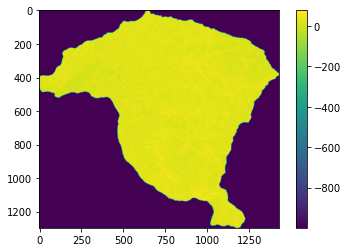

In [3]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/Pendiente.tif')
pendiente=raster.read(1)
fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(pendiente)
plt.colorbar(im, ax=ax, label="Pendiente (°)")
ax.set_title("Mapa de Pendiente — Cuenca La Miel", fontsize=13)
ax.set_xlabel("Columna (píxeles)")
ax.set_ylabel("Fila (píxeles)")
plt.tight_layout()

El mapa aparece con solo los dos colores de los extremos observados en la escala, pareciendo que todos los valores dentro de la cuenca son 0. Sin embargo, esto se debe al contraste entre los valores por fuera de la cuenca, es decir celdas que no son de la cuenca y que al parecer tienen valores negativos muy grandes; y los valores de pendiente solo varian entre 0 y 90°. Por lo tanto se debe modificar y cambiar los valores de cuenca por NaN (*no data*), los cuales Python pueda interpretar adecuadamente.

En este caso se utiliza la función *np.where*, que para este caso cambia todos los valores menores a 0, y que para el caso del mapa de pendiente son celdas que no son cuenca. Y para los valores que no cumplen esta condición dejar el valor que trae el mapa. 

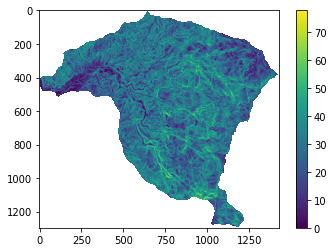

In [4]:
pendiente=np.where(pendiente<0,np.nan,pendiente)
fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(pendiente, cmap="YlOrRd")
plt.colorbar(im, ax=ax, label="Pendiente (°)")
ax.set_title("Mapa de Pendiente (valores NoData eliminados) — Cuenca La Miel", fontsize=13)
ax.set_xlabel("Columna (píxeles)")
ax.set_ylabel("Fila (píxeles)")
plt.tight_layout()

Si observamos, estos mapas corresponden a matrices, es decir un arreglo de filas y columnas con valores, que en este caso representan la pendiente de cada celda en un área igual a la resolución espacial del raster.

In [ ]:
type(pendiente)

numpy.ndarray

Para explorar las variables es entonces recomendable pasarlas de matrices a vectores, y formar con todas las variables tipo vector un *Dataframe*, el cual corresponde a un objeto de la libreria *Pandas*, que facilita enormente el trabajo con estas grandes cantidades de datos. Las dimensiones de esta matriz son:

In [ ]:
np.shape(pendiente)

(1297, 1430)

Para convertirlo a vector se utliza la función *ravel* y se eliminan de dicho vector los NaN, que son las celdas que no son cuenca.

In [5]:
pendiente_vector=pendiente.ravel()  # para pasarlo a un vector
pendiente_vector_MenM=pendiente_vector[~np.isnan(pendiente_vector)] # para eliminar  del vector los datos NaN
pendiente_vector_MenM.shape # otra forma de saber las dimensiones

(910801,)

Antes de generar el *Dataframe* con las diferentes variables, es necesario entonces importar todas las variables y realizar los ajustes que sean necesarios.

(910801,)

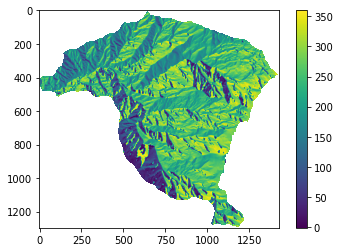

In [7]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/Aspecto.tif')
aspecto=raster.read(1)
aspecto=np.where(aspecto<-100,np.nan,aspecto)
aspecto_vector=aspecto.ravel()
aspecto_vector_MenM=aspecto_vector[~np.isnan(aspecto_vector)]
plt.imshow(aspecto)
plt.colorbar()
aspecto_vector_MenM.shape

Es importante revisar que todos los mapas den como resultado un vector con las mismas filas, en caso contrario no se permitirá construir el *Dataframe*.

(910801,)

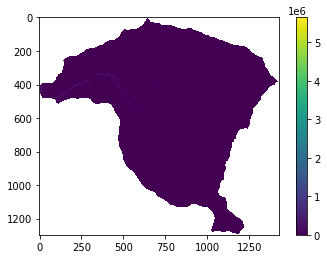

In [8]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/FlujoAcumulado.tif')
flujo=raster.read(1)
flujo=np.where(flujo<0,np.nan,flujo)
flujo_vector=flujo.ravel()
flujo_vector_MenM=flujo_vector[~np.isnan(flujo_vector)]
plt.imshow(flujo)
plt.colorbar()
flujo.shape
flujo_vector_MenM.shape

(910801,)

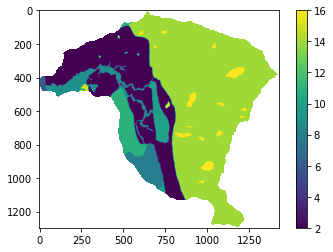

In [9]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/Geologia_Superficial.tif')
geologia=raster.read(1)
geologia=np.where(geologia<0,np.nan,geologia)
geologia_vector=geologia.ravel()
geologia_vector_MenM=geologia_vector[~np.isnan(geologia_vector)]
plt.imshow(geologia)
plt.colorbar()
geologia_vector_MenM.shape

Existen otras librearias para importar como *gdal*, en las cuales el procedimiento varía ligeramente. Para saber cuantas clases tiene un mapa de variables categóricas se utiliza la función unique de numpy.

In [ ]:
np.unique(geologia)

array([ 2.,  4.,  6.,  8.,  9., 10., 11., 14., 15., 16., nan])

Finalmente, importamos el inventario y utilizamos como máscara el mapa de pendientes, y modificamos los valores para que las celdas con movimientos en masa tengan un valor de 1, y las celdas sin movimientos en masa un valor de 0, las celdas que no son de la cuenca tienen NaN.

(910801,)

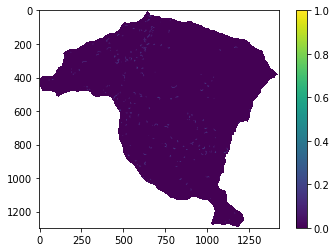

In [10]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/Inventario_MenM.tif')
inventario=raster.read(1)
raster_mask = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/Pendiente.tif')
msk=raster_mask.read_masks(1)
msk=np.where(msk==255,1,np.nan)
inventario=msk*inventario
inventario_vector=inventario.ravel()
inventario_vector_MenM=inventario_vector[~np.isnan(inventario_vector)]
plt.imshow(inventario)
plt.colorbar()
inventario_vector_MenM.shape

Finalmente para crear el *Dataframe* con las variables predictoras incluidas, se crea primero un diccionario y luego se transforma a un *Dataframe*:

In [11]:
d={'inventario':inventario_vector_MenM,'pendiente':pendiente_vector_MenM,'flujo_acum':flujo_vector_MenM,'aspecto':aspecto_vector_MenM, 'geologia':geologia_vector_MenM}
df = pd.DataFrame(d)
print(list(df.columns))

['inventario', 'pendiente', 'flujo_acum', 'aspecto', 'geologia']


Un *Dataframe* corresponde a una tabla donde las columnas son las variables y las filas son cada observación, en este caso las celdas que componen la cuenca. Los objetos tipo *Dataframe* permiten utilizar la función *head* o *tail* para conocer las primeras o últimas filas de la tabla.

In [12]:
df.head()

,inventario,pendiente,flujo_acum,aspecto,geologia
0,0.0,10.862183,0.0,208.523560,14.0
1,0.0,12.265345,0.0,207.437332,14.0
2,0.0,12.469252,0.0,202.684647,14.0
3,0.0,13.148026,0.0,211.619766,14.0
4,0.0,14.091524,0.0,220.028976,14.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 910801 entries, 0 to 910800
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   inventario  910801 non-null  float64
 1   pendiente   910801 non-null  float32
 2   flujo_acum  910801 non-null  float32
 3   aspecto     910801 non-null  float32
 4   geologia    910801 non-null  float64
dtypes: float32(3), float64(2)
memory usage: 24.3 MB


### Muestreo
Para el análisis exploratorio y selección de variables no es estrictamente necesario realizar un muestreo del *Dataframe*. Todo lo contrario, lo ideal es poder trabajar con el *Dataframe* completo. Sin embargo, existen algunas funciones, especialmente de la librería *seaborn* que pueden ser computacionalmente muy exigentes y tardar demasiado los resultados. Es por esto que a continuación se crea un nuevo *Dataframe* que toma del original todas las celdas que tienen movimiento en masa, y adicionalmente el 10% de las celdas sin movimientos en masa de forma aleatoria. Esta forma aleatoria implica que cada vez que se corran los resultados, estos varían ligeramente.

In [13]:
df1=df[(df["inventario"]==1) | (df["inventario"]==0).sample(frac=.1)]
df1.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 92528 entries, 1 to 910786
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   inventario  92528 non-null  float64
 1   pendiente   92528 non-null  float32
 2   flujo_acum  92528 non-null  float32
 3   aspecto     92528 non-null  float32
 4   geologia    92528 non-null  float64
dtypes: float32(3), float64(2)
memory usage: 3.2 MB


In [ ]:
resumen=df1.describe().T
print(resumen)

              count         mean            std  min         25%         50%  \
inventario  92541.0     0.017506       0.131147  0.0    0.000000    0.000000   
pendiente   92541.0    29.208084      11.466265  0.0   21.736065   29.615969   
flujo_acum  92541.0  2913.954102  101789.039062  0.0    4.000000   11.000000   
aspecto     92541.0   213.038864     100.410477 -1.0  152.242233  236.783127   
geologia    92541.0    10.206590       5.178208  2.0    2.000000   14.000000   

                   75%           max  
inventario    0.000000  1.000000e+00  
pendiente    36.881142  7.577515e+01  
flujo_acum   25.000000  5.650063e+06  
aspecto     291.094452  3.599973e+02  
geologia     14.000000  1.600000e+01  


In [14]:
matriz=df.drop(['inventario'],axis=1) # función para eliminar una columna (axis=1)
matriz.head()

,pendiente,flujo_acum,aspecto,geologia
0,10.862183,0.0,208.523560,14.0
1,12.265345,0.0,207.437332,14.0
2,12.469252,0.0,202.684647,14.0
3,13.148026,0.0,211.619766,14.0
4,14.091524,0.0,220.028976,14.0


In [15]:
matriz_cont=matriz.drop(['geologia'],axis=1)
matriz_cont.head()

,pendiente,flujo_acum,aspecto
0,10.862183,0.0,208.523560
1,12.265345,0.0,207.437332
2,12.469252,0.0,202.684647
3,13.148026,0.0,211.619766
4,14.091524,0.0,220.028976


### Análisis de todas las variables

Con esta matriz se puede explorar la relación entre las variables. Para el primer caso utilizamos sólo las variables continuas y usando la función de *Pandas*; y para el segundo caso utilizamos toda la matriz separando los datos de acuerdo con el inventario, con la librería de *seaborn*.

In [ ]:
pd.plotting.scatter_matrix(matriz_cont, alpha = 0.3, figsize = (14,10), diagonal='kde');

In [ ]:
sns.pairplot(df1, hue='inventario');

Para conocer la histograma de densidad de distribución se utiliza la siguiente función:

In [ ]:
matriz.plot(kind='density', subplots=True, layout=(2, 2), sharex=False, figsize=(10, 4));

Para conocer la correlación lineal entre las variables se puede utilizar la siguiente función para objetos tipo *Dataframe*.

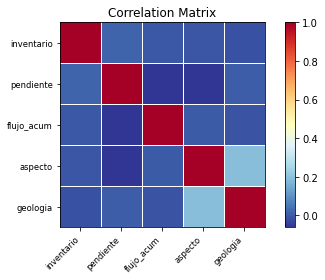

In [ ]:
MatCorre=DataFrame(df.corr())
smg.plot_corr(MatCorre, xnames=list(MatCorre.columns)) ;

### Análisis univariado

In [ ]:
df.pendiente.hist()
plt.title('Histograma de Pendiente')
plt.xlabel('Pendiente')
plt.ylabel('Frecuencia')

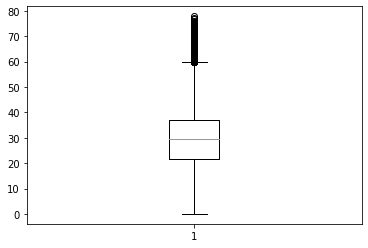

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))
ax.boxplot(df['pendiente'])
ax.set_title("Distribución de Pendiente (°)", fontsize=13)
ax.set_ylabel("Pendiente (°)")
ax.set_xticklabels(["Pendiente"])
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

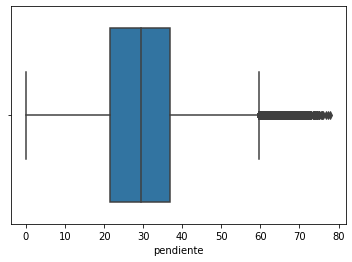

In [ ]:
sns.boxplot(x='pendiente', data=df);

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


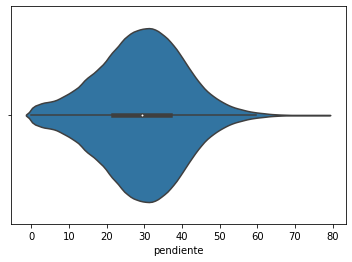

In [ ]:
sns.violinplot(df['pendiente']);

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


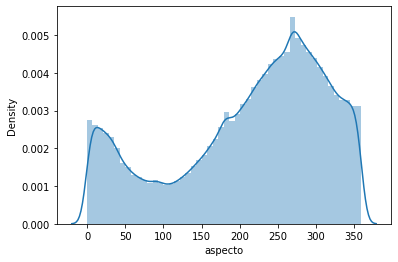

In [ ]:
sns.distplot(df['aspecto']);

### Análisis multivariado

In [ ]:
sns.jointplot(x='aspecto', y='flujo_acum', data=df1, kind='scatter');

In [ ]:
sns.jointplot(x='pendiente', y='flujo_acum', data=df1, kind='kde', color='g');

In [ ]:
sns.scatterplot(x="pendiente", y="aspecto", hue="inventario", size='pendiente',data=df1);

In [ ]:
sns.lmplot('flujo_acum', 'pendiente', data=df1, hue='inventario', fit_reg=False);

### Correlación con la variable dependiente

Para saber la media de cada variable independiente de acuerdo con la variable dependiente utilizamos la función *groupby*:

In [ ]:
media=df.groupby('inventario').mean()
print(media)

            pendiente   flujo_acum     aspecto   geologia
inventario                                               
0.0         29.082050  2915.758057  213.785950  10.233438
1.0         34.459793    21.809259  199.425674   8.787037


In [ ]:
#Para contar el numero de celdas con y sin MenM
df['inventario'].value_counts()

0.0    909181
1.0      1620
Name: inventario, dtype: int64

Es importante también crear dos nuevos *Dataframe* solo con las celdas que presenta movimientos en masa y otro con las celdas sin movimientos en masa.

In [16]:
landslides=df.inventario.astype(bool)
si_lands=df[landslides]
no_lands=df[~landslides]

In [ ]:
si_lands.count()

inventario    1620
pendiente     1620
flujo_acum    1620
aspecto       1620
geologia      1620
dtype: int64

In [ ]:
no_lands.count()

inventario    909181
pendiente     909181
flujo_acum    909181
aspecto       909181
geologia      909181
dtype: int64

De esta forma podemos empezar a mirar la capacidad de separación o predicción de cada variable: una herraeminta puede ser los diagramas de cajas con *notch*.

/usr/local/lib/python3.7/dist-packages/matplotlib/cbook/__init__.py:1376: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  X = np.atleast_1d(X.T if isinstance(X, np.ndarray) else np.asarray(X))


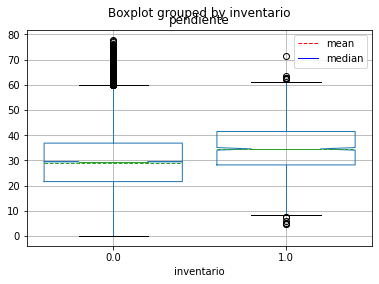

In [ ]:
fig, ax = plt.subplots(figsize=(6,5))
df.boxplot('pendiente', by='inventario', notch=True, widths=0.8, showmeans=True, meanline=True, ax=ax)
plt.plot([], [], '--', linewidth=1, color='red', label='mean')
plt.plot([], [], '-', linewidth=1, color='blue', label='median')
plt.legend();
ax.set_title("Pendiente según Presencia de Movimiento en Masa", fontsize=12)
ax.set_xlabel("Inventario (0=Sin MenM, 1=Con MenM)")
ax.set_ylabel("Pendiente (°)")
plt.suptitle("")
plt.tight_layout()

Para confirmar si las dos poblaciones pendientes con MenM y pendientes sin MenM son poblaciones diferentes, se puede realizar una prueba de hipótesis (*Ttest*) de la siguiente forma:

In [ ]:
from scipy import stats
stats.ttest_ind(no_lands["pendiente"], si_lands["pendiente"])

Ttest_indResult(statistic=-18.772609621435528, pvalue=1.3092661545639284e-78)

Al obtener un valor menor al 5% confirma que la diferencia es estadísticamente significativa, por lo tanto la pendiente es una buena variable que permite diferenciar las celdas con y sin MenM.

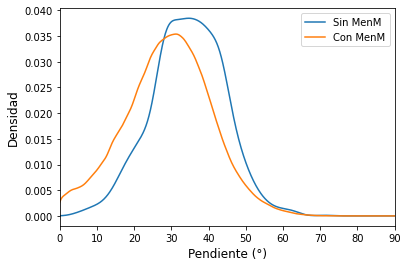

In [17]:
fig, ax = plt.subplots(figsize=(8,5))
ax.set_title("Densidad de Probabilidad — Pendiente por Presencia de Deslizamiento", fontsize=12)
si_lands['pendiente'].plot.kde(ax=ax, label='Sin MenM')
no_lands['pendiente'].plot.kde(ax=ax, label='Con MenM')
ax.set_xlim(0,90)
ax.set_xlabel('Pendiente (°)', color='k', size=12)
ax.set_ylabel('Densidad', color='k', size=12)
ax.legend(loc=1, fontsize=10)
ax.tick_params('y', colors='k', labelsize= 10)

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


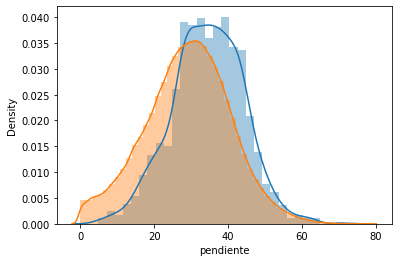

In [19]:
sns.distplot(si_lands['pendiente'])
sns.distplot(no_lands['pendiente']);

### Análisis de Componentes Principales (PCA)

El PCA es un método de *machine learning* no supervisado  para reducir dimensionalmente un modelo con una gran cantidad de variables. Para esta reducción permite identificar las variables que mas le aportan a la varianza del modelo. En este ejemplo vamos a utilizar un conjunto de variables importados desde una tabla de excel.

A continuación se presenta el código en Python que permite obtener el número de componentes principales a partir de una serie de vectores. Para esto se debe primero transformar los datos para escalarlos. El número de componentes obtenidos es igual al mismo número de variables o vectores que se ingresan. cada componente principal corresponde a una combinación lineal de las variables originales. Los componentes principales desde el punto de vista de algebra lineal corresponden a los vectores propios asociados a los valores propios de la matriz de covarianza. De esta forma cada componente principal es una nueva variable ortogonal a todos los demas componentes ortogonales, y cada uno de ellos representa un vector propio y la varianza del total de información que conserva.

El análisis de PCA organiza los componentes principales de mayor a menor varianza. La primera gráfica que se obtiene es el porcentaje de varianza que representa cada componente principal, siendo el componente principal 1 el que mayor varianza del total de la información representa. La segunda gráfica corresponde a la varianza acumulada de los componentes, iniciando desde el primero de ellos. Finalmente, se grafica el componente principal 1 contra el componente principal 2 y se proyectan los datos sobre estos dos nuevos ejes; al igual que se grafican las anteriores ejes que corresponden a las variables originales. Esto significa que se puede obtener de esta última grafica las variables colineales y las variables que mas información propia aportan y que ayudan a separar entre celdas con MenM y sin MenM.

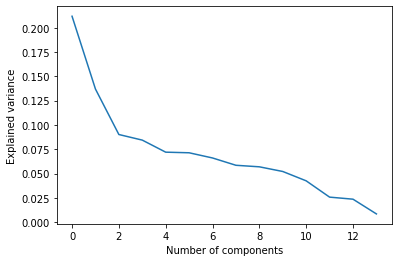

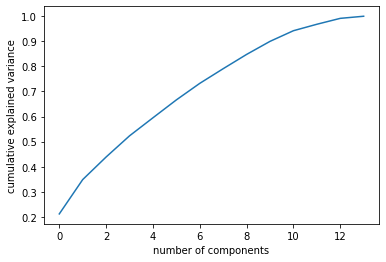

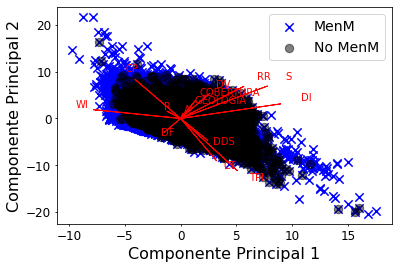

In [ ]:
#se importan todas las librerias a utilizar
from sklearn.decomposition import PCA
from sklearn.preprocessing import scale

#Se importan los archivos
data= pd.read_excel("https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/PUNTOS.xlsx", sheet_name='PUNTOS')
puntos=data['INVENTARIO']
data.drop('INVENTARIO', axis=1, inplace=True)

# Se debe escalar los datos antes de aplicar PCA
data = pd.DataFrame(scale(data), columns=['DV', 'A', 'CP', 'CT', 'DF', 'GEOLOGIA','RR','R','S','TPI','WI','COBERTURA','DDS','DI'])

## Se implementa el análisi PCA con la libreria sklearn de python
n = len(data.columns)
pca = PCA(n_components=n)
pca = pca.fit(data)
pca_samples = pca.transform(data)

#Se puede graficar cuanto aporta a la varianza cada componente generado
plt.plot(pca.explained_variance_ratio_)
plt.xlabel('Number of components')
plt.ylabel('Explained variance')
plt.show()

#graficamos el acumulado de varianza explicada en las nuevas dimensiones
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.show()

#Para identificar cada variable como se relaciona con las componentes utilizamos las figuras byplot de python
# 0,1 denota el componente princiapl 1 y 2 (PC1 and PC2); para otros componentes se modifica el número
xvector = pca.components_[0] 
yvector = pca.components_[1]

xs = pca.transform(data)[:,0] # Componente principal 1
ys = pca.transform(data)[:,1] # Componente principal 2

mask1=np.ma.masked_where(puntos < 1,xs )
mask2=np.ma.masked_where(puntos < 1,ys ) 

## Para visualizar las proyecciones de cada variable en los componentes se utiliza la siguiente función
for i in range(len(xvector)):
# arrows project features (ie columns from csv) as vectors onto PC axes
    plt.arrow(0, 0, xvector[i]*max(xs), yvector[i]*max(ys),
              color='r', width=0.0005, head_width=0.0025)
    plt.text(xvector[i]*max(xs)*1.2, yvector[i]*max(ys)*1.2,
             list(data.columns.values)[i], color='r') 

plt.scatter(xs, ys, s=70,marker='x',c='blue', label='MenM')
plt.scatter(mask1,mask2,facecolors='black', edgecolors='black', s=70, alpha=0.5, label='No MenM')
plt.tick_params('y', colors='k', labelsize=12, length=2)
plt.tick_params('x', colors='k', labelsize= 12, length=2)
plt.xlabel("Componente Principal 1", fontsize=16)
plt.ylabel("Componente Principal 2", fontsize=16)
plt.legend(fontsize=14)
plt.show()

Finalmente, se presenta una función que grafica el valor de la varianza que explica cada componente y el aporte de cada variable en cada componente.

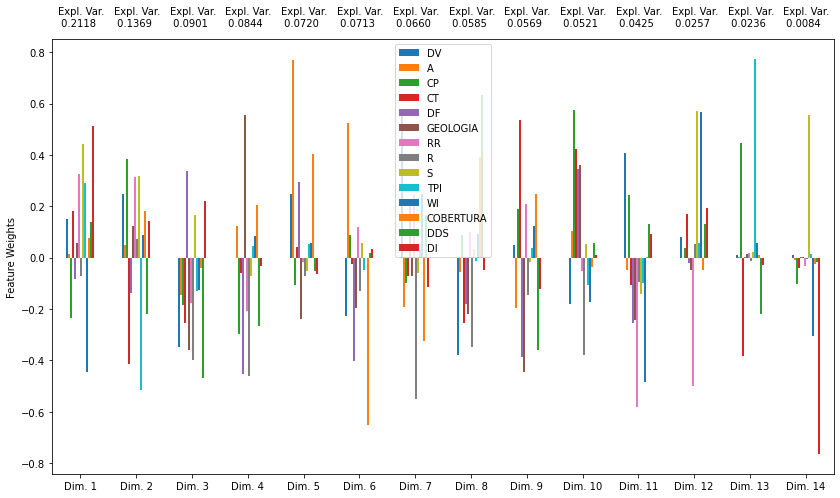

In [ ]:
def pca_results(data, pca):
    
    dimensions = ['Dim. {}'.format(i) for i in range(1,len(pca.components_)+1)]
    
    components = pd.DataFrame(np.round(pca.components_, 4), columns = data.keys()) 
    components.index = dimensions

    ratios = pca.explained_variance_ratio_.reshape(len(pca.components_), 1) 
    variance_ratios = pd.DataFrame(np.round(ratios, 4), columns = ['Explained Variance']) 
    variance_ratios.index = dimensions

    fig, ax = plt.subplots(figsize = (14,8))

    components.plot(ax = ax, kind = 'bar')
    ax.set_ylabel("Feature Weights") 
    ax.set_xticklabels(dimensions, rotation=0)

    for i, ev in enumerate(pca.explained_variance_ratio_): 
        ax.text(i-0.40, ax.get_ylim()[1] + 0.05, "Expl. Var.\n %.4f"%(ev))

    return pd.concat([variance_ratios, components], axis = 1)

pca_results = pca_results(data, pca)

## Análisis vectorial con GeoPandas

Además de los datos raster, el análisis de variables condicionantes frecuentemente requiere capas vectoriales (polígonos de geología, fallas, unidades de suelo). `geopandas` permite cargar, visualizar y cruzar estas capas con el inventario de movimientos en masa.


In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import BytesIO

# ── Cargar capa vectorial de geología superficial ─────────────────────────────
# (si existe en el repositorio como shapefile/geojson)
url_geo = ('https://github.com/edieraristizabal/Libro_cartoGeotecnia/'
           'raw/refs/heads/master/data/miel/Geologia_Superficial.shp')

try:
    geo_vector = gpd.read_file(url_geo)
    print('CRS:', geo_vector.crs)
    print('Columnas:', geo_vector.columns.tolist())
    print('Unidades geológicas:', geo_vector.shape[0])
except Exception:
    # Si el shapefile no está disponible, crear GeoDataFrame de ejemplo
    print('Shapefile no disponible — generando ejemplo con datos sintéticos')
    from shapely.geometry import Point
    import numpy as np
    np.random.seed(42)
    n = 50
    geo_vector = gpd.GeoDataFrame({
        'unidad':     np.random.choice(['Qal', 'Tmc', 'Jgr', 'Pzm'], n),
        'n_menm':     np.random.poisson(3, n),
        'geometry':   [Point(x, y) for x, y in
                       zip(np.random.uniform(840000, 860000, n),
                           np.random.uniform(1160000, 1190000, n))]
    }, crs='EPSG:3116')  # Magna-Colombia Bogotá

# ── Análisis por unidad geológica ─────────────────────────────────────────────
if 'n_menm' in geo_vector.columns or True:
    # Estadísticas por unidad geológica
    if 'unidad' in geo_vector.columns:
        resumen = (geo_vector.groupby('unidad')['n_menm']
                   .agg(['sum', 'mean', 'count'])
                   .rename(columns={'sum': 'Total MenM', 'mean': 'Promedio/polígono',
                                    'count': 'Num. polígonos'})
                   .sort_values('Total MenM', ascending=False))
        print('\n=== Movimientos en masa por unidad geológica ===')
        print(resumen.to_string())

        # Gráfico de barras
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))

        resumen['Total MenM'].plot.bar(ax=axes[0], color='steelblue',
                                       edgecolor='k', alpha=0.85)
        axes[0].set_title('Total de Movimientos en Masa\npor Unidad Geológica',
                          fontsize=12)
        axes[0].set_xlabel('Unidad Geológica')
        axes[0].set_ylabel('Número de Movimientos en Masa')
        axes[0].tick_params(axis='x', rotation=30)
        axes[0].grid(axis='y', alpha=0.3)

        resumen['Promedio/polígono'].plot.bar(ax=axes[1], color='tomato',
                                              edgecolor='k', alpha=0.85)
        axes[1].set_title('Promedio de Movimientos por Polígono\npor Unidad Geológica',
                          fontsize=12)
        axes[1].set_xlabel('Unidad Geológica')
        axes[1].set_ylabel('Movimientos / polígono')
        axes[1].tick_params(axis='x', rotation=30)
        axes[1].grid(axis='y', alpha=0.3)

        plt.tight_layout()
        plt.show()

# ── Mapa vectorial básico ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 8))
if 'unidad' in geo_vector.columns:
    geo_vector.plot(column='unidad', ax=ax, legend=True, cmap='Set2',
                    legend_kwds={'title': 'Unidad geológica', 'loc': 'lower right'})
else:
    geo_vector.plot(ax=ax, color='lightcoral', edgecolor='k', alpha=0.7)
ax.set_title('Mapa de Unidades Geológicas Superficiales — Cuenca La Miel', fontsize=13)
ax.set_xlabel('Este (m)')
ax.set_ylabel('Norte (m)')
plt.tight_layout()
plt.show()


## Actividades

1. **Nueva variable:** Agrega la variable *curvatura de la ladera* (curvatura de perfil o planta) como predictor. Calcula su distribución estadística y compara con el boxplot de pendiente. ¿Tiene mayor o menor poder discriminante respecto al inventario?

2. **Correlación entre predictores:** Construye una matriz de correlación de Pearson entre todas las variables numéricas del DataFrame. ¿Cuáles pares presentan multicolinealidad alta (|r| > 0.7)? ¿Cómo afectaría esto a los modelos estadísticos del capítulo 09?

3. **PCA interpretado:** Reproduce el análisis PCA del notebook e interpreta los dos primeros componentes en términos geomorfológicos. ¿Qué proceso físico resume cada componente? ¿Qué porcentaje de varianza capturan?

4. **Manejo de NoData:** El mapa de pendiente tiene celdas con valor negativo que se interpretan como NoData. Escribe una función genérica `limpiar_raster(arr, nodata_val)` que reemplace estos valores con `np.nan` y valide que el array resultante tiene al menos el 90% de celdas válidas.

## Referencias
```{bibliography}
:style: plain
:filter: docname in docnames
```